# Desenvolvimento do modelo de XGBoost Classifier - Binário
---

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from xgboost import XGBClassifier

### 2. Pacotes Predexan
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Buscando em: {caminho_predexan}")
print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Buscando em: C:\Users\rmaca\PUC_eixo7\projeto\pmv-si-2026-1-pe7-t3-g1-pesquisaexperimentacao-2026-1\src
Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

A escolha de target **provisória** é `label` por conta da razão utilidade/custo computacional, mas ainda será ***conversado com o professor*** a possibilidade de se voltar a usar `categoria_ataque`, mesmo que este não tenha sido processado de forma eficiente pelas máquinas a disposição, em primeiro momento. 

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')
# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')
# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


## D) Desenvolvimento do Modelo de XGBoost Classifier
---

### 1. Aplicação da classe SMOTE para balanceamento de classes nas variáveis de treino
---

- Target **label**:

O uso da classe `SMOTE`se mostra **injustificado** para o target `label` uma vez que ele já está naturalmente balanceado na base de treino.

In [8]:
# df_treino['label'].value_counts()

### 2. Treino do modelo
---

#### 2.1. Instanciando a classe XGBClassifier
---

In [9]:
modelo = XGBClassifier(objective='binary:logistic', learning_rate=0.2, max_depth=3, n_estimators=40, scale_pos_weight=1.72, random_state=42, eval_metric='auc')

**Explicando os parâmetros utilizados em XGBClassifier:**

- `objective='binary:logistic'` -> Define que o problema é de `classificação binária`, ou seja, prever duas classes (True/False, 0/1)
  
- `eval_metric='error'` -> Métrica de avaliação usada durante o treino. Aqui, “error” significa a taxa de erro de classificação (proporção de previsões incorretas)

- `learning_rate=0.2` -> Também chamado de eta. Controla o tamanho do passo em cada atualização. Valores menores tornam o aprendizado mais lento, mas podem melhorar a generalização

- `max_depth=3` -> Profundidade máxima das árvores de decisão. Árvores rasas (como 1) reduzem complexidade e ajudam a evitar overfitting (decorar os dados), mas podem limitar a capacidade de capturar relações complexas.

- `n_estimators=40` -> Número de árvores (ou rodadas de boosting) que serão treinadas. Mais árvores aumentam a capacidade do modelo, mas também o risco de overfitting se não houver regularização. Havia atribuído 10, mas aumentei o número de árvores para aumentar precisão

- `scale_pos_weight=1.72` -> Equilibra os pesos positivos e negativos. O valor de 1.72 representa a razão (proporção) entre a quantidade de registros da classe negativa (tráfego normal) e a classe positiva (ataques) para garantir que o algoritmo não ignore os ataques devido à maior frequência de tráfego legítimo, equilibrando a sensibilidade do modelo. 


#### 2.2. Calibração do modelo com a classe CalibratedClassifierCV
---

Modelos `XGBoost` achatam as probabilidades e são muito "confiantes", de modo a retornar, frequentemente, muito próximas de `0%` ou `100%`. Desta forma, é necessário calibrá-los, usando a classe `CalibratedClassifierCV` do módulo `calibration` de `Sci-kit Learn`. 

##### 2.2.1. Calibração
---

In [10]:
modelo_calibrado = CalibratedClassifierCV(estimator=modelo, method='sigmoid', cv=5)

##### 2.2.2. Explicação dos hiperparâmetros
---

- `estimator=modelo` -> Define qual o modelo base, que no caso, foi o instanciado no tópico `2.1.` da seção `D)`.
- `method='sigmoid'` -> Escolhe o algoritmo matemático de calibração. O 'sigmoid' (ou Platt Scaling) passa os resultados do modelo por uma função logística. É ideal para datasets menores.
- `cv=5` -> Ativa a Validação Cruzada em 5 partes (folds). O modelo divide os dados de treino, treina o XGBoost em uma parte e calibra na outra. Isso evita overfitting, garantindo que o calibrador seja ajustado com base em previsões que o XGBoost nunca viu antes. A escolha de 5 foi por ser padrão da indústria.

#### 2.3. Treino do modelo
---

Para o treino do modelo, é usada a expressão `modelo.fit(X_treino, y_treino)`. Será rodado em conjunto com a função `imprimir_tempo()` do módulo `metricas` do pacote `Predexan`, para poder ter o tempo de processamento registrado: 

In [11]:
pm.imprimir_desempenho(modelo_calibrado.fit,X_treino, y_treino)


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 23/05/2026 18:03:17

1. TEMPO: 3.0472s (0.05 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 158.08 MB
   - Diferença líquida de RAM no processo: 68.00 MB
   - Total RAM alocada para o processo: 435.44 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 33.5%

Execução concluída em: 23/05/2026 18:03:20



CalibratedClassifierCV(cv=5,
                       estimator=XGBClassifier(base_score=None, booster=None,
                                               callbacks=None,
                                               colsample_bylevel=None,
                                               colsample_bynode=None,
                                               colsample_bytree=None,
                                               device=None,
                                               early_stopping_rounds=None,
                                               enable_categorical=False,
                                               eval_metric='auc',
                                               feature_types=None, gamma=None,
                                               grow_policy=None,
                                               importance_type=None,
                                               interaction_constraints=None,
                                               learning_rate=0.2, max_bin=None,
                                               max_cat_threshold=None,
                                               max_cat_to_onehot=None,
                                               max_delta_step=None, max_depth=3,
                                               max_leaves=None,
                                               min_child_weight=None,
                                               missing=nan,
                                               monotone_constraints=None,
                                               multi_strategy=None,
                                               n_estimators=40, n_jobs=None,
                                               num_parallel_tree=None,
                                               random_state=42, ...))

### 3. Realização de predições com os dados de teste
---

Para a predição probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo.predict_proba(X_teste)`. Para a predição binária, é expresso da mesma forma, mas com o uso do método `predict()`. Ambas terão seu desempenho medido pela função `imprimir_desempenho()` de `Predexan`.

#### 3.1. Predição Probababilística
---

Para a predição probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo.predict_proba(X_teste)`

In [12]:
y_predicao_probabilistica = pm.imprimir_desempenho(modelo_calibrado.predict_proba, X_teste)[:,1]


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 23/05/2026 18:03:20

1. TEMPO: 0.4191s (0.01 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 3.49 MB
   - Diferença líquida de RAM no processo: 5.29 MB
   - Total RAM alocada para o processo: 440.85 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 17.0%

Execução concluída em: 23/05/2026 18:03:20



#### 3.2. Predição Binária
---

Para a Predição Binária, é usado o método `predict()` na seguinte expressão: `modelo.predict(X_teste)`

In [13]:
y_predicao_binaria = pm.imprimir_desempenho(modelo_calibrado.predict, X_teste)


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 23/05/2026 18:03:20

1. TEMPO: 0.3251s (0.01 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 3.49 MB
   - Diferença líquida de RAM no processo: 0.07 MB
   - Total RAM alocada para o processo: 440.92 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 26.6%

Execução concluída em: 23/05/2026 18:03:20



In [14]:
type(y_predicao_binaria)

numpy.ndarray

### 4. Desempenho do modelo
---

O modelo possui métricas de desempenho baseadas nos resultados dos testes, sendo essas: 

- `Pontuação` que traz a `Acurácia Geral`.
- `Matriz de Confusão` que traz os acertos e erros de inferência.
-  `Relatório de Classificação` que traz cálculos como `Precision`, `Recall` e `F1-Score`.
-  `Curva ROC AUC` que traz uma visualização gráfica.

#### 4.1. Matriz de Confusão
---

A `Matriz de Confusão` permite a visualização do desempenho do modelo, uma vez que mostra o total de predições `Verdadeiras Positivas (TP)`, `Verdadeiras Negativa (TN)`, `Falsas Positivas (FP)` e `Falsas Negativas (FN)`. No contexto do projeto, que visa a probailidade de `detecção de ameaças`, os alvos são sempre atingir ao máximo`TN` e `TP`, mas `FN` é o erro crítico, pois pode levar ao usuário da aplicação a ignorar a hipótese do ataque em sua máquina, podendo propiciar uma piora no caso, já que este pode deixar de buscar ajuda e manutenções e `FP` é o alarme falso. 

##### 4.1.1. Criação da Matriz de Confusão 
---

In [15]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)

##### 4.1.2. Visualização da Matriz de Confusão 
---

<Axes: >

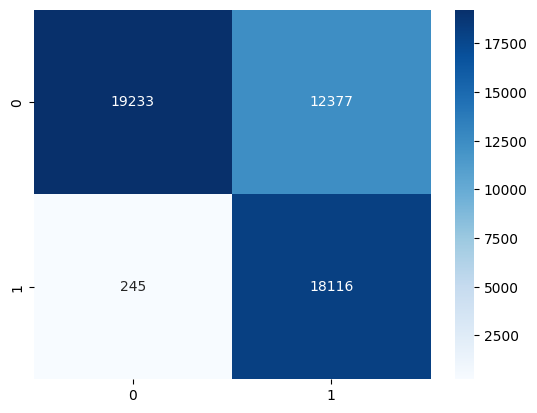

In [16]:
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues')

##### 4.1.3. Análises da Matriz de Confusão
---

In [17]:
(tn, fp), (fn, tp) = matriz_confusao
total = (tn+fn+tp+fp)

In [18]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 19233 casos que o modelo apontou como resultado negativo, corretamente. Representa 38.49% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 245 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 0.49% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 18116 casos em que o modelo apontou como resultado positivo, corretamente. Representa 36.25% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 12377 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 24.77% do total de predições 

#### 4.2. Pontuação do Modelo (Acurácia Geral)
---

A `Acurácia Geral` tem como foco apontar quantas predições foram assertivas no total. Pode ser uma métrica errônea em conjuntos de dados desbalanceados. Em situações como essa, o modelo pode investir nos casos mais óbvios e deixando a resposta "pré-programada", como um chute, deixando uma acurácia alta e uma eficiência baixa. Dessa forma, esta métrica deve se analisada sempre em conjunto com as demais para garantir o sucesso do modelo.

##### 4.2.1. Criação e visualização da Pontuação do Modelo
---

In [19]:
acuracia = modelo_calibrado.score(X_teste, y_teste)
print(f'O percentual de acurácia atual do modelo é de, aproximadamente, {(acuracia * 100):.2f}%.')

O percentual de acurácia atual do modelo é de, aproximadamente, 74.74%.


#### 4.3. Relatório de Classificação
---

O `Relatório de Classificação` apresenta métricas de desempenho que mostram o quanto o modelo acerta, utilizando as noções da `Matriz de Confusão` como TN, FN, TP, FP.

1. Precision (Precisão): tem como foco evitar Alarmes Falsos (Falsos Positivos). Uma precisão alta significa que o modelo é cauteloso ao rotular algo como positivo

<div style="text-align: center;">
  <img src="../../imagens/formula_precisao.png" width="400">
</div>

2. Recall (Revocação): tem como foco evitar omissões do modelo. Um recall alto significa que o modelo consegue percorrer por quase todos os casos importantes, mesmo que arrisque alguns alarmes falsos, mas evite falsos negativos.

<div style="text-align: center;">
  <img src="../../imagens/formula_recall.png" width="400">
</div>

3. F1-Score (Valor F1): É a média harmônica entre Precision e Recall. Boa métrica para perceber quando se tem classes desbalanceadas e precisa de um único número que resuma a eficiência da predição.

<div style="text-align: center;">
  <img src="../../imagens/formula_f1score.png" width="400">
</div>

##### 4.3.1. Criação e visualização do Relatório de Classificação
---

In [20]:
relatorio_classificacao = classification_report(y_teste, y_predicao_binaria)

In [21]:
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.99      0.61      0.75     31610
         1.0       0.59      0.99      0.74     18361

    accuracy                           0.75     49971
   macro avg       0.79      0.80      0.75     49971
weighted avg       0.84      0.75      0.75     49971



#### 4.4. Curva ROC AUC
---

A curva `ROC (Receiver Operating Characteristic)` e a métrica `AUC (Area Under the Curve)` são ferramentas muito importantes para a medição de desempenho de `Modelos de Classificação`. Ela mede a capacidade do modelo em distinguir as classes: quanto maior o AUC, melhor o modelo é em prever 0 como 0 e 1 como 1, mas ainda assim, é melhor para medir o desempenho das probabilidades com o método `predict_proba` do que com o `predict`.

1. Curva ROC: É um gráfico que ilustra o equilíbrio entre a Taxa de Verdadeiros Positivos (Sensibilidade) e a Taxa de Falsos Positivos (1 - Especificidade) para todos os limiares (thresholds) possíveis de classificação.

2. AUC (Área sob a Curva): É um valor numérico que varia de 0 a 1 e resume a performance do modelo:

   - 1.0: Classificador perfeito.

   - 0.5: Classificador aleatório (equivalente ao acaso).

   -  Acima de 0.7: Geralmente indica um bom poder preditivo.
  
3. Os eixos são os seguintes:

    - Eixo Y (Taxa de Verdadeiro Positivo / Sensibilidade): Representa o Recall. Quanto mais alto, melhor para o modelo, já que este será mais abrangente ao processar os dados, conseguindo capturar um maior número de ameaças.

    - Eixo X (Taxa de Falso Positivo): É o custo do erro. Ele mostra, em relação a todos os casos normais, quantos o modelo marcou erradamente como ameaça. Quanto mais baixo (à esquerda), melhor.
  
4. A "Linha de Sorte" (Pontilhada):

    - A linha diagonal representa um modelo que decide com aleatoriedade.

    - Se curva estiver próximo a essa linha diagonal, ele será pouco útil.
  
    - Se estiver acima, mais distante, terá uma utilidade maior, por não depender tanto de aleatoriedade.
  
5. O Ponto Ideal:

    O objetivo do modelo é chegar o mais próximo possível do canto superior esquerdo (coordenada 0.0 no X e 1.0 no Y). 

##### 4.4.1. Plot do gráfico da Curva ROC AUC
---

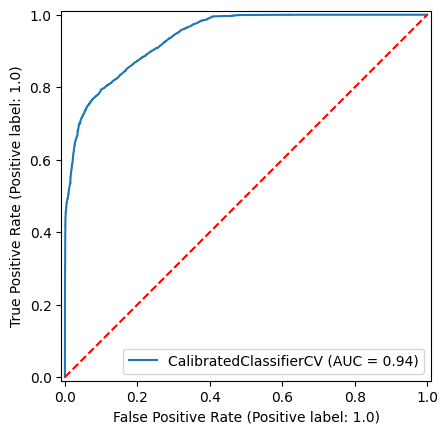

In [22]:
curva = RocCurveDisplay.from_estimator(modelo_calibrado, X_teste, y_teste)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.show()

##### 4.4.2. Plot do gráfico da Curva Precision-Recall
---

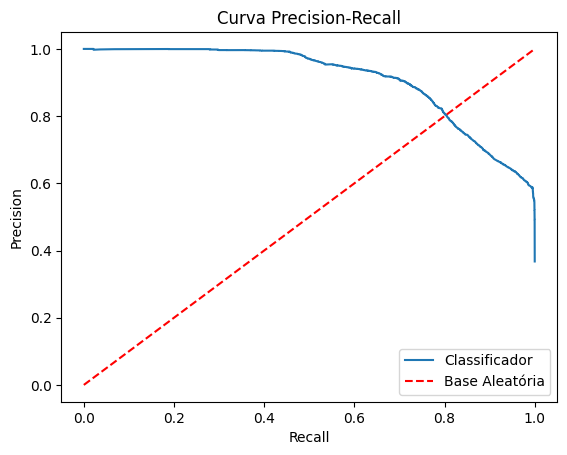

In [23]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica)

In [33]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True, obj_f2=True)


--- Objetivo focado em Recall (meta = 95.0%) ---
Limiar ideal a ser usado: 0.7165
Recall real obtido: 95.00% (Ataques detectados)
Precision real obtida: 63.93% (Acerto dos alertas disparados)

--- Objetivo focado em Precision (meta >= 95.0%) ---
Limiar ideal a ser usado: 0.9077
Recall real obtido: 56.71% (Ataques detectados)
Precision real obtida: 95.00% (Acerto dos alertas disparados)

--- Equilíbrio Simétrico (Max F1-Score) ---
Limiar ideal: 0.8757
Recall neste ponto: 76.64% (Ataques detectados)
Precision neste ponto: 85.46% (Acerto dos alertas)

--- Equilíbrio Otimizado para Recall (Max F2-Score) ---
Limiar ideal: 0.1119
Recall neste ponto: 99.53% (Ataques detectados)
Precision neste ponto: 58.74% (Acerto dos alertas)


In [28]:
y_predicao_probabilistica_customizada = (y_predicao_probabilistica > 0.8384).astype(int)

<Axes: >

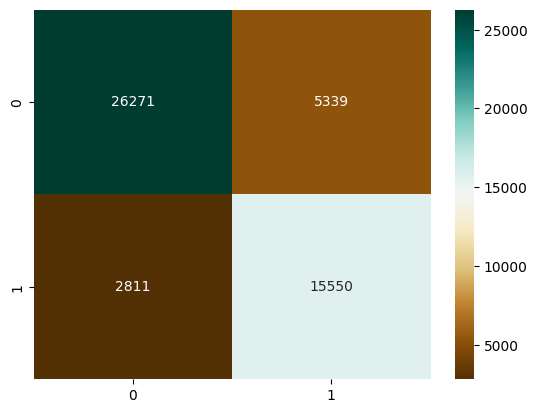

In [29]:
matriz_confusao_customizada = confusion_matrix(y_teste, y_predicao_probabilistica_customizada)
sns.heatmap(matriz_confusao_customizada, annot=True, fmt='d', cmap='BrBG')

In [30]:
(tn, fp), (fn, tp) = matriz_confusao_customizada
total = (tn+fn+tp+fp)

In [31]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 26271 casos que o modelo apontou como resultado negativo, corretamente. Representa 52.57% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 2811 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 5.63% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 15550 casos em que o modelo apontou como resultado positivo, corretamente. Representa 31.12% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 5339 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 10.68% do total de predições 

In [32]:
relatorio_classificacao = classification_report(y_teste, y_predicao_probabilistica_customizada)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.90      0.83      0.87     31610
         1.0       0.74      0.85      0.79     18361

    accuracy                           0.84     49971
   macro avg       0.82      0.84      0.83     49971
weighted avg       0.84      0.84      0.84     49971



## 5. Visualização da Relevância das Features
---

In [25]:
# Determinar as features de X_treino
relevancia_features = modelo_calibrado.feature_importances_
cols_feature_treino = X_treino.columns

# Criação do df_relevancia para facilitar a criação do gráfico de barras
df_relevancia = pd.DataFrame({'Feature':cols_feature_treino, 'Relevância':relevancia_features})
df_relevancia = df_relevancia.sort_values(by='Relevância', ascending=False) # Organiza as barras à partir dos valores de relevância, do maior para o menor

# Criação do gráfico
plt.figure(figsize=(10, 6))
sns.barplot(x='Relevância', y='Feature', data=df_relevancia, palette='viridis', hue='Feature')

# Customização do gráfico
plt.title('Features mais relevantes, do maior para o menor', fontsize=14)
plt.xlabel('Nível de Relevância', fontsize=12)
plt.ylabel('Atributos', fontsize=12)
plt.show()

AttributeError: 'CalibratedClassifierCV' object has no attribute 'feature_importances_'

In [ ]:
print(df_relevancia.head(36)) 